### matplotlib: Anwendungen - Übungen

In diesem Notebook setzt du numpy und matplotlib zusammen ein: Funktionen untersuchen und zeichnen, Wachstum modellieren,
Messdaten auswerten, Zufallsexperimente und Vorgänge aus Physik und Biologie simulieren, geometrische Figuren konstruieren und
**Fraktale** wie die Mandelbrot-Menge berechnen.

Vorausgesetzt werden die Notebooks *matplotlib: Grundlagen*, *Diagrammtypen* und *Layout* sowie *numpy: Mathematik*
und *numpy: Zufall und Statistik*. Für die Fraktale brauchst du **Rekursion** aus dem Notebook *Funktionen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen die Übungen. Unter den meisten Aufgaben siehst du das **erwartete Diagramm**. Zeichne es nach und vergleiche.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Kurvendiskussion

#### Eine Funktion untersuchen und zeichnen

Mit den Polynom-Funktionen aus *numpy: Mathematik* berechnet man die besonderen Punkte und zeichnet sie gleich ein:

- Nullstellen: `np.roots(f)`
- Extremstellen: Nullstellen von `np.polyder(f)`, die Art über das Vorzeichen von `np.polyder(f, 2)`
- Wendestellen: Nullstellen von `np.polyder(f, 2)`
- Funktionswerte: `np.polyval(f, x)`

Mit `ax.annotate()` beschriftet man die Punkte, mit `ax.axhline(0)` und `ax.axvline(0)` zeichnet man die Koordinatenachsen.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f = np.array([1, -3, 0, 2])     # x³ - 3x² + 2
x = np.linspace(-1.5, 3.5, 200)
null = np.sort(np.roots(f))
extrem = np.sort(np.roots(np.polyder(f)))
fig, ax = plt.subplots()
ax.plot(x, np.polyval(f, x))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.plot(null, np.zeros(len(null)), 'ro', label='Nullstellen')
ax.plot(extrem, np.polyval(f, extrem), 'gs', label='Extrempunkte')
ax.legend()
plt.show()
print(np.round(null, 3))
print(np.round(extrem, 3))

#### Aufgabe 1.1

Zeichne `f` von -3 bis 4 mit Koordinatenachsen (schwarz, Dicke 0.8) und markiere die Nullstellen mit roten Kreisen. Gib die Nullstellen sortiert aus (3 Stellen).

**Erwartete Ausgabe:**
```
[-2.  1.  3.]
```

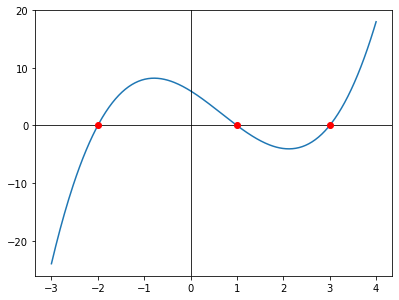

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
null = np.sort(np.roots(f))
fig, ax = plt.subplots()
ax.plot(x, np.polyval(f, x))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.plot(null, np.zeros(3), 'ro')
plt.show()
print(np.round(null, 3))
```

</details>

#### Aufgabe 1.2

Zeichne `f`, markiere Hochpunkt (grünes Dreieck `'g^'`) und Tiefpunkt (grünes Dreieck nach unten `'gv'`) und schreibe mit `ax.annotate()` und Pfeil `HP` bzw. `TP`
an die Stellen 0.7 rechts und 2 Einheiten über bzw. unter den Punkten. Die Art ergibt sich aus dem Vorzeichen der zweiten Ableitung.

**Erwartete Ausgabe:**

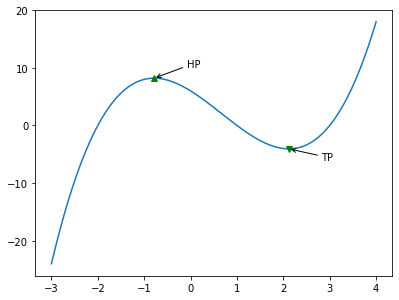

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
f1 = np.polyder(f)
f2 = np.polyder(f, 2)
fig, ax = plt.subplots()
ax.plot(x, np.polyval(f, x))
for xe in np.roots(f1):
    ye = np.polyval(f, xe)
    if np.polyval(f2, xe) < 0:
        ax.plot(xe, ye, 'g^')
        ax.annotate('HP', xy=(xe, ye), xytext=(xe + 0.7, ye + 2), arrowprops=dict(arrowstyle='->'))
    else:
        ax.plot(xe, ye, 'gv')
        ax.annotate('TP', xy=(xe, ye), xytext=(xe + 0.7, ye - 2), arrowprops=dict(arrowstyle='->'))
plt.show()
```

</details>

#### Aufgabe 1.3

Zeichne `f`, `f'` und `f''` in drei Diagramme untereinander mit gemeinsamer x-Achse (Größe 6 × 7) mit den Titeln `f`, `f'`, `f''` und jeweils einer schwarzen Linie bei y = 0.
Zeichne in alle drei Diagramme graue gestrichelte senkrechte Linien bei den Extremstellen von `f`.

**Erwartete Ausgabe:**

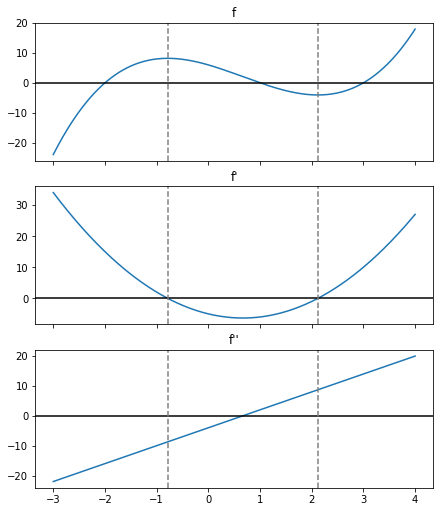

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
ableitungen = [f, np.polyder(f), np.polyder(f, 2)]
extrem = np.roots(np.polyder(f))
fig, axs = plt.subplots(3, 1, figsize=(6, 7), sharex=True, layout='constrained')
for ax, p, name in zip(axs, ableitungen, ['f', "f'", "f''"]):
    ax.plot(x, np.polyval(p, x))
    ax.axhline(0, color='black')
    for xe in extrem:
        ax.axvline(xe, color='gray', linestyle='--')
    ax.set_title(name)
plt.show()
```

</details>

#### Aufgabe 1.4

Zeichne `f` und die Tangente an der Stelle `x0 = -1` (rot gestrichelt, über den ganzen Bereich), dazu den Berührpunkt als schwarzen Kreis. Setze `ax.set_ylim(-15, 15)`.
Gib die Tangentengleichung als `y = m·x + b` aus (m und b auf zwei Stellen gerundet).

**Erwartete Ausgabe:**
```
y = 2·x + 10
```

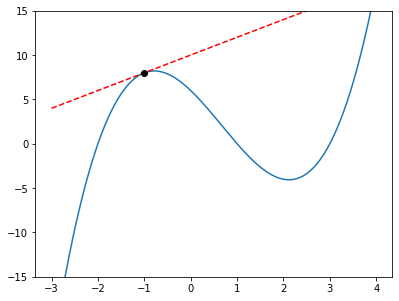

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
x0 = -1
m = np.polyval(np.polyder(f), x0)
b = np.polyval(f, x0) - m * x0
fig, ax = plt.subplots()
ax.plot(x, np.polyval(f, x))
ax.plot(x, m * x + b, 'r--')
ax.plot(x0, np.polyval(f, x0), 'ko')
ax.set_ylim(-15, 15)
plt.show()
print(f'y = {np.round(m, 2)}·x + {np.round(b, 2)}')
```

</details>

#### Aufgabe 1.5

Zeichne `f` und färbe die Flächen zwischen dem Graphen und der x-Achse zwischen der kleinsten und der größten Nullstelle: oberhalb der Achse grün, unterhalb rot (Deckkraft 0.3).
Berechne die Gesamtfläche (Beträge der Teilintegrale zwischen benachbarten Nullstellen mit `np.polyint()`) und gib sie auf drei Stellen gerundet aus.

**Erwartete Ausgabe:**
```
21.083
```

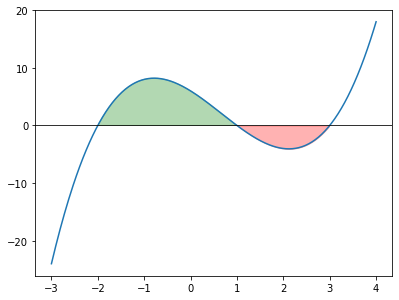

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, -2, -5, 6])     # x³ - 2x² - 5x + 6
x = np.linspace(-3, 4, 300)
null = np.sort(np.roots(f))
xf = np.linspace(null[0], null[-1], 300)
yf = np.polyval(f, xf)
fig, ax = plt.subplots()
ax.plot(x, np.polyval(f, x))
ax.axhline(0, color='black', linewidth=0.8)
ax.fill_between(xf, yf, where=yf > 0, color='green', alpha=0.3)
ax.fill_between(xf, yf, where=yf < 0, color='red', alpha=0.3)
plt.show()
F_ = np.polyint(f)
flaeche = 0
for i in range(len(null) - 1):
    flaeche += abs(np.polyval(F_, null[i + 1]) - np.polyval(F_, null[i]))
print(np.round(flaeche, 3))
```

</details>

#### Aufgabe 1.6

Zeichne die Funktion `g(x) = x · e^(-x)` von 0 bis 6 (200 Punkte), finde ihren Hochpunkt näherungsweise mit `argmax()` auf dem Array der Funktionswerte
und markiere ihn mit einem roten Kreis. Gib die Stelle und den Wert auf zwei Stellen gerundet aus.

**Erwartete Ausgabe:**
```
0.99 0.37
```

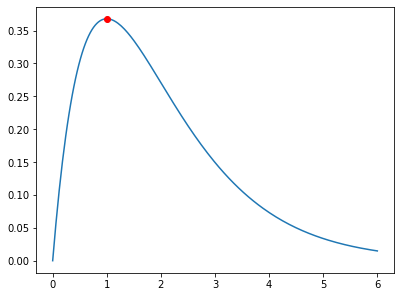

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 6, 200)
y = x * np.exp(-x)
i = y.argmax()
fig, ax = plt.subplots()
ax.plot(x, y)
ax.plot(x[i], y[i], 'ro')
plt.show()
print(np.round(x[i], 2), np.round(y[i], 2))
```

</details>

## 2. Funktionsscharen und Wachstumsmodelle

#### Parameter verändern

Bei einer **Funktionsschar** hängt die Funktion von einem Parameter ab, z. B. `f_a(x) = a · sin(x)`. Zeichnet man mehrere Werte von `a`
in ein Diagramm oder nebeneinander, sieht man, was der Parameter bewirkt.

**Wachstumsmodelle** beschreiben, wie eine Größe mit der Zeit zunimmt:

| Modell | Formel | Beispiel |
|---|---|---|
| linear | `B(t) = B0 + d·t` | Sparschwein mit festem Betrag pro Monat |
| exponentiell | `B(t) = B0 · q^t` | Zinseszins, Bakterien ohne Begrenzung |
| beschränkt | `B(t) = S - (S - B0) · e^(-k·t)` | Erwärmung eines Getränks auf Raumtemperatur |
| logistisch | `B(t) = S / (1 + (S/B0 - 1) · e^(-k·t))` | Ausbreitung eines Gerüchts, Tierpopulation |

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 20, 200)
B0, S = 10, 100
fig, ax = plt.subplots()
ax.plot(t, B0 + 4 * t, label='linear')
ax.plot(t, B0 * 1.15 ** t, label='exponentiell')
ax.plot(t, S - (S - B0) * np.exp(-0.2 * t), label='beschränkt')
ax.plot(t, S / (1 + (S / B0 - 1) * np.exp(-0.4 * t)), label='logistisch')
ax.axhline(S, color='gray', linestyle=':')
ax.set_ylim(0, 150)
ax.legend()
plt.show()

#### Aufgabe 2.1

Zeichne die Schar `f_a(x) = a · sin(x)` für `a` = 0.5, 1, 2 von 0 bis 2π (200 Punkte) mit Labels `a = 0.5` usw. und Legende.

**Erwartete Ausgabe:**

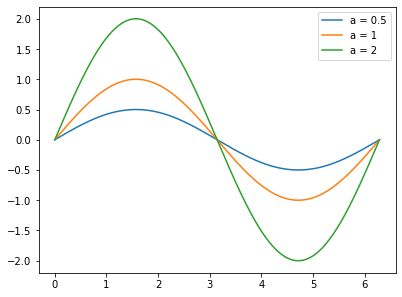

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots()
for a in [0.5, 1, 2]:
    ax.plot(x, a * np.sin(x), label=f'a = {a}')
ax.legend()
plt.show()
```

</details>

#### Aufgabe 2.2

Zeichne in drei Diagrammen nebeneinander (Größe 10 × 3, gemeinsame y-Achse) die Wirkung der Parameter von `a · sin(b · (x - c))` von 0 bis 2π (300 Punkte):
links `a` = 1, 2, 3 (b = 1, c = 0), Mitte `b` = 1, 2, 3 (a = 1, c = 0), rechts `c` = 0, 1, 2 (a = 1, b = 1). Titel `a`, `b`, `c`.

**Erwartete Ausgabe:**

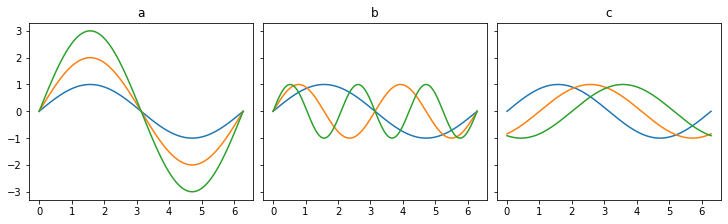

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 2 * np.pi, 300)
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True, layout='constrained')
for k in [1, 2, 3]:
    axs[0].plot(x, k * np.sin(x))
    axs[1].plot(x, np.sin(k * x))
for c in [0, 1, 2]:
    axs[2].plot(x, np.sin(x - c))
for ax, name in zip(axs, ['a', 'b', 'c']):
    ax.set_title(name)
plt.show()
```

</details>

#### Aufgabe 2.3

Zeichne die Parabelschar `f_k(x) = x² - k·x` für `k` von -3 bis 3 (ganze Zahlen) von -4 bis 4 (100 Punkte) mit Farben aus der Skala `'coolwarm'` (Farbe `skala((k + 3) / 6)`).
Markiere den Scheitelpunkt jeder Parabel (`k/2`, `-k²/4`) mit einem schwarzen Punkt und verbinde die Scheitel mit einer gestrichelten schwarzen Linie (die **Ortskurve**).

**Erwartete Ausgabe:**

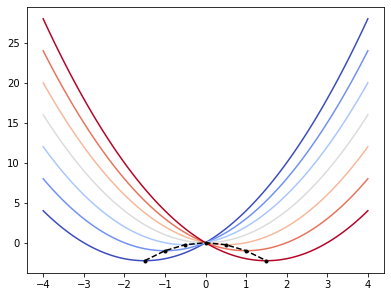

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-4, 4, 100)
skala = plt.colormaps['coolwarm']
ks = np.arange(-3, 4)
fig, ax = plt.subplots()
for k in ks:
    ax.plot(x, x ** 2 - k * x, color=skala((k + 3) / 6))
ax.plot(ks / 2, -ks ** 2 / 4, 'k.--')
plt.show()
```

</details>

#### Aufgabe 2.4

Ein Getränk mit 6 °C steht in einem 22 °C warmen Raum und erwärmt sich beschränkt: `T(t) = 22 - 16 · e^(-0.05·t)` (t in Minuten).
Zeichne `T` von 0 bis 90 Minuten mit einer gestrichelten grauen Linie bei 22 °C und gib aus, nach wie vielen Minuten (ganzzahlig, `np.arange(0, 91)`) es zum ersten Mal mindestens 15 °C hat.

**Erwartete Ausgabe:**
```
17
```

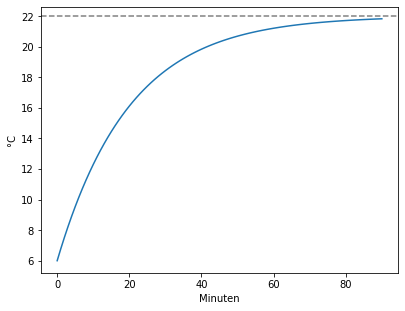

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
t = np.arange(0, 91)
T = 22 - 16 * np.exp(-0.05 * t)
fig, ax = plt.subplots()
ax.plot(t, T)
ax.axhline(22, color='gray', linestyle='--')
ax.set_xlabel('Minuten')
ax.set_ylabel('°C')
plt.show()
print(t[T >= 15][0])
```

</details>

#### Aufgabe 2.5

Ein Gerücht verbreitet sich in einer Schule mit 800 Personen logistisch: `B(t) = 800 / (1 + 799 · e^(-0.9·t))` (t in Stunden, am Anfang kennt es eine Person).
Zeichne `B` von 0 bis 15 Stunden (200 Punkte) und daneben (zweites Diagramm, Größe 9 × 3) die Zunahme pro Stunde als Näherung `np.diff(B) / np.diff(t)`.
Titel: `Wer kennt das Gerücht?` und `Zunahme pro Stunde`.

**Erwartete Ausgabe:**

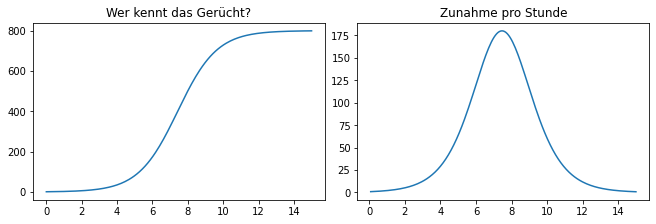

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
t = np.linspace(0, 15, 200)
B = 800 / (1 + 799 * np.exp(-0.9 * t))
fig, axs = plt.subplots(1, 2, figsize=(9, 3), layout='constrained')
axs[0].plot(t, B)
axs[0].set_title('Wer kennt das Gerücht?')
axs[1].plot(t[1:], np.diff(B) / np.diff(t))
axs[1].set_title('Zunahme pro Stunde')
plt.show()
```

</details>

#### Aufgabe 2.6

Vergleiche zwei Sparpläne über 40 Jahre (ganze Jahre): Plan A startet mit 1000 Euro und bekommt jedes Jahr 100 Euro dazu (ohne Zinsen),
Plan B startet mit 500 Euro und bekommt 7 % Zinsen. Zeichne beide mit Legende und markiere das erste Jahr, in dem B mehr wert ist als A, mit einer senkrechten grauen Linie. Gib das Jahr aus.

**Erwartete Ausgabe:**
```
32
```

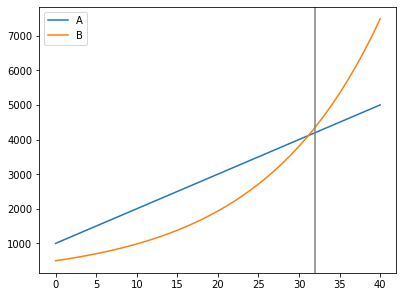

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
jahre = np.arange(41)
a = 1000 + 100 * jahre
b = 500 * 1.07 ** jahre
j = jahre[b > a][0]
fig, ax = plt.subplots()
ax.plot(jahre, a, label='A')
ax.plot(jahre, b, label='B')
ax.axvline(j, color='gray')
ax.legend()
plt.show()
print(j)
```

</details>

## 3. Messdaten auswerten

#### Messdaten, Regression und Residuen

Zu einer guten Auswertung gehören drei Diagramme:

1. die **Messpunkte** mit der angepassten Kurve (`np.polyfit()`),
2. die **Residuen** (Messwert minus Kurvenwert): Liegen sie zufällig um 0, passt das Modell. Zeigen sie ein Muster, fehlt etwas im Modell,
3. bei exponentiellen Vorgängen die Darstellung mit **logarithmischer** Achse: Dort wird die Kurve zur Geraden.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1, 2, 3, 4, 5, 6, 7, 8])
y = np.array([2.9, 5.2, 9.8, 17.1, 26.0, 37.2, 50.1, 65.3])
gerade = np.polyfit(x, y, 1)
parabel = np.polyfit(x, y, 2)
xs = np.linspace(1, 8, 100)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
axs[0].scatter(x, y)
axs[0].plot(xs, np.polyval(gerade, xs), label='Gerade')
axs[0].plot(xs, np.polyval(parabel, xs), label='Parabel')
axs[0].legend()
axs[1].scatter(x, y - np.polyval(gerade, x), label='Gerade')
axs[1].scatter(x, y - np.polyval(parabel, x), label='Parabel')
axs[1].axhline(0, color='black')
axs[1].set_title('Residuen')
axs[1].legend()
plt.show()

#### Aufgabe 3.1

Eine Feder wird mit Gewichten belastet. Zeichne die Messpunkte und die Regressionsgerade (rot, von 0 bis 300 g), beschrifte die Achsen mit `Masse (g)` und `Länge (cm)`.
Gib die Steigung (cm pro g, 4 Stellen) und die Länge ohne Gewicht (2 Stellen) aus.

**Erwartete Ausgabe:**
```
0.0503 10.01
```

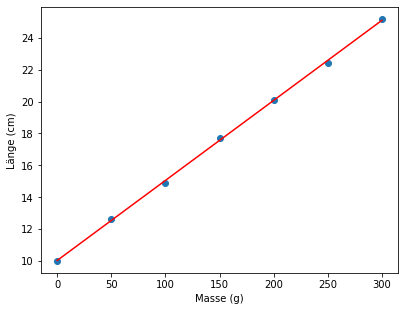

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
m, b = np.polyfit(masse, laenge, 1)
xs = np.array([0, 300])
fig, ax = plt.subplots()
ax.scatter(masse, laenge)
ax.plot(xs, m * xs + b, color='red')
ax.set_xlabel('Masse (g)')
ax.set_ylabel('Länge (cm)')
plt.show()
print(np.round(m, 4), np.round(b, 2))
```

</details>

#### Aufgabe 3.2

Zeichne die Residuen der Federmessung als Punkte mit einer schwarzen Linie bei 0 und `ax.set_ylim(-0.5, 0.5)`.

**Erwartete Ausgabe:**

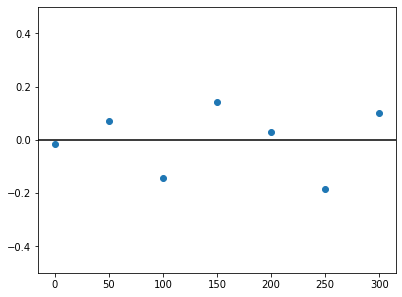

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
gerade = np.polyfit(masse, laenge, 1)
fig, ax = plt.subplots()
ax.scatter(masse, laenge - np.polyval(gerade, masse))
ax.axhline(0, color='black')
ax.set_ylim(-0.5, 0.5)
plt.show()
```

</details>

#### Aufgabe 3.3

Zeichne die Messpunkte mit Fehlerbalken von ± 0.3 cm (`errorbar`, nur Punkte, `capsize=4`) und die Regressionsgerade.

**Erwartete Ausgabe:**

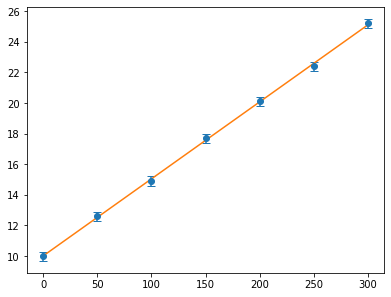

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
masse = np.array([0, 50, 100, 150, 200, 250, 300])   # g
laenge = np.array([10.0, 12.6, 14.9, 17.7, 20.1, 22.4, 25.2])   # cm
gerade = np.polyfit(masse, laenge, 1)
fig, ax = plt.subplots()
ax.errorbar(masse, laenge, yerr=0.3, fmt='o', capsize=4)
ax.plot(masse, np.polyval(gerade, masse))
plt.show()
```

</details>

#### Aufgabe 3.4

Bakterien vermehren sich. Zeichne die Messpunkte in zwei Diagrammen nebeneinander (Größe 9 × 3.5): links mit normaler, rechts mit logarithmischer y-Achse.
Titel `normal` und `logarithmisch`.

**Erwartete Ausgabe:**

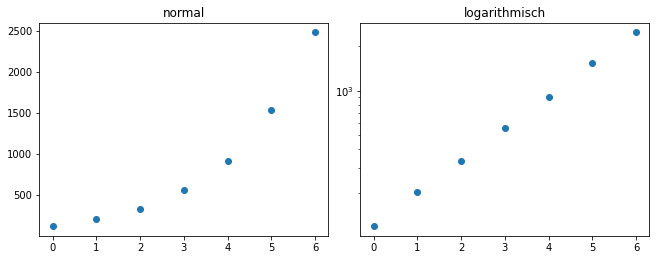

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
t = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 205, 330, 560, 910, 1530, 2480])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
t = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 205, 330, 560, 910, 1530, 2480])
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
for ax in axs:
    ax.scatter(t, anzahl)
axs[1].set_yscale('log')
axs[0].set_title('normal')
axs[1].set_title('logarithmisch')
plt.show()
```

</details>

#### Aufgabe 3.5

Passe ein exponentielles Modell `N(t) = a · e^(k·t)` an: Gerade durch `(t, ln(anzahl))` mit `np.polyfit()`, dann `a = e^b`. Zeichne die Messpunkte und das Modell (0 bis 6, 100 Punkte)
mit logarithmischer y-Achse. Gib `k` und `a` (zwei Stellen) und die Verdopplungszeit `ln(2)/k` (zwei Stellen) aus.

**Erwartete Ausgabe:**
```
0.5 121.69
1.37
```

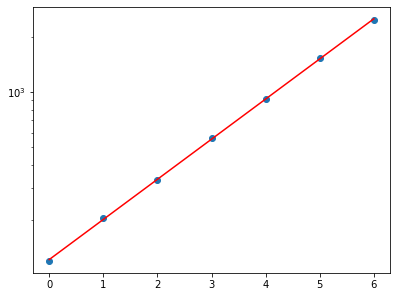

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
t = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 205, 330, 560, 910, 1530, 2480])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
t = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 205, 330, 560, 910, 1530, 2480])
k, b = np.polyfit(t, np.log(anzahl), 1)
a = np.exp(b)
ts = np.linspace(0, 6, 100)
fig, ax = plt.subplots()
ax.scatter(t, anzahl)
ax.plot(ts, a * np.exp(k * ts), color='red')
ax.set_yscale('log')
plt.show()
print(np.round(k, 2), np.round(a, 2))
print(np.round(np.log(2) / k, 2))
```

</details>

#### Aufgabe 3.6

Vergleiche drei Modelle für die Bremswege: Zeichne die Messpunkte und Regressionspolynome vom Grad 1, 2 und 4 (Labels `Grad 1` usw.) von 20 bis 140 km/h
mit Legende und `ax.set_ylim(0, 200)`. Der Grad 4 passt zwar genau durch die Punkte, sagt aber außerhalb Unsinn voraus.

**Erwartete Ausgabe:**

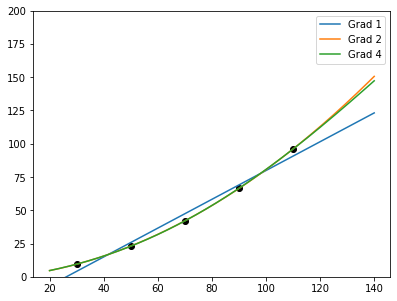

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
v = np.array([30, 50, 70, 90, 110])
weg = np.array([9.5, 23.0, 42.0, 66.5, 96.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
v = np.array([30, 50, 70, 90, 110])
weg = np.array([9.5, 23.0, 42.0, 66.5, 96.0])
vs = np.linspace(20, 140, 200)
fig, ax = plt.subplots()
ax.scatter(v, weg, color='black')
for grad in [1, 2, 4]:
    ax.plot(vs, np.polyval(np.polyfit(v, weg, grad), vs), label=f'Grad {grad}')
ax.set_ylim(0, 200)
ax.legend()
plt.show()
```

</details>

## 4. Simulationen mit Zufall

#### Zufall sichtbar machen

Viele Zufallsexperimente versteht man erst, wenn man sie oft wiederholt und das Ergebnis zeichnet:

- **Irrfahrten** (zufällige Schritte) als Linie oder als Weg in der Ebene,
- **Häufigkeiten** als Balken oder Histogramm,
- **Zufallspunkte** als Streudiagramm (z. B. für Monte-Carlo-Verfahren).

Alle Aufgaben verwenden einen festen Seed, damit dein Bild genau wie das erwartete aussieht.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
winkel = rng.uniform(0, 2 * np.pi, size=1000)
x = np.cumsum(np.cos(winkel))
y = np.cumsum(np.sin(winkel))
fig, ax = plt.subplots()
ax.plot(x, y, linewidth=0.8)
ax.plot(0, 0, 'go')
ax.plot(x[-1], y[-1], 'ro')
ax.set_aspect('equal')
plt.show()

#### Aufgabe 4.1

**Irrfahrt in der Ebene:** Ein Käfer macht 500 Schritte der Länge 1 in zufällige Richtungen (`rng.uniform(0, 2 * np.pi, size=500)`). Zeichne seinen Weg,
den Start als grünen und das Ende als roten Kreis, mit gleichen Einheiten. Gib die Entfernung vom Start am Ende aus (zwei Stellen).

**Erwartete Ausgabe:**
```
10.39
```

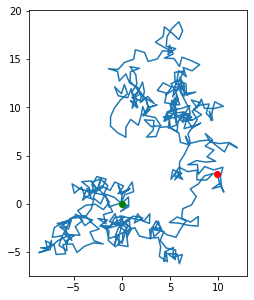

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(2)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(2)
w = rng.uniform(0, 2 * np.pi, size=500)
x = np.cumsum(np.cos(w))
y = np.cumsum(np.sin(w))
fig, ax = plt.subplots()
ax.plot(x, y)
ax.plot(0, 0, 'go')
ax.plot(x[-1], y[-1], 'ro')
ax.set_aspect('equal')
plt.show()
print(np.round(np.sqrt(x[-1] ** 2 + y[-1] ** 2), 2))
```

</details>

#### Aufgabe 4.2

**Galton-Brett:** Eine Kugel fällt durch 10 Reihen von Nägeln und geht an jedem zufällig nach links (0) oder rechts (1). Das Fach ist die Anzahl der Rechts-Schritte.
Simuliere 2000 Kugeln mit `rng.integers(0, 2, size=(2000, 10)).sum(axis=1)` und zeichne die Häufigkeiten der Fächer 0 bis 10 als Balken (`np.bincount(..., minlength=11)`).

**Erwartete Ausgabe:**

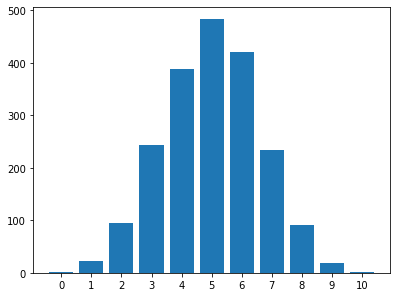

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(3)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(3)
faecher = rng.integers(0, 2, size=(2000, 10)).sum(axis=1)
fig, ax = plt.subplots()
ax.bar(range(11), np.bincount(faecher, minlength=11))
ax.set_xticks(range(11))
plt.show()
```

</details>

#### Aufgabe 4.3

**Zentraler Grenzwertsatz:** Die Summe vieler Zufallszahlen ist ungefähr normalverteilt. Zeichne vier Histogramme nebeneinander (Größe 10 × 2.5, 30 Klassen):
die Summe von 1, 2, 5 und 20 Zufallszahlen aus `rng.random((10000, n))` (in dieser Reihenfolge, `sum(axis=1)`). Titel `n = 1` usw.

**Erwartete Ausgabe:**

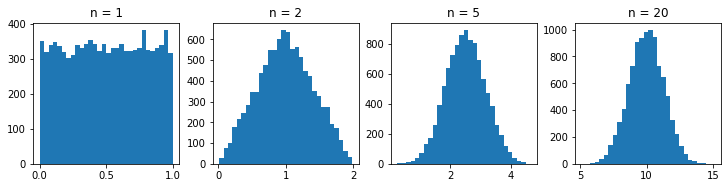

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(4)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(4)
fig, axs = plt.subplots(1, 4, figsize=(10, 2.5), layout='constrained')
for ax, n in zip(axs, [1, 2, 5, 20]):
    ax.hist(rng.random((10000, n)).sum(axis=1), bins=30)
    ax.set_title(f'n = {n}')
plt.show()
```

</details>

#### Aufgabe 4.4

**Monte-Carlo-Integration:** Schätze die Fläche unter `f(x) = x²` von 0 bis 1 mit 2000 Zufallspunkten im Einheitsquadrat (`rng.random(2000)` für x, danach für y).
Zeichne die Punkte unter der Kurve blau und darüber grau (Größe 3) und die Kurve schwarz. Gib den Anteil der Punkte unter der Kurve aus (exakt: 1/3).

**Erwartete Ausgabe:**
```
0.3305
```

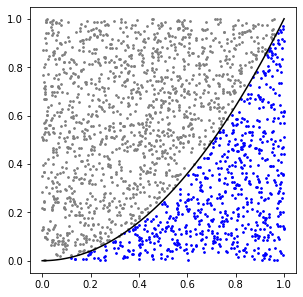

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(5)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(5)
x = rng.random(2000)
y = rng.random(2000)
unter = y <= x ** 2
xs = np.linspace(0, 1, 100)
fig, ax = plt.subplots()
ax.scatter(x[unter], y[unter], s=3, color='blue')
ax.scatter(x[~unter], y[~unter], s=3, color='gray')
ax.plot(xs, xs ** 2, color='black')
ax.set_aspect('equal')
plt.show()
print(unter.mean())
```

</details>

#### Aufgabe 4.5

**Würfelrennen:** Drei Figuren starten bei 0 und ziehen in 30 Runden jeweils die gewürfelte Augenzahl vor (`rng.integers(1, 7, size=(3, 30))`, kumuliert pro Zeile).
Zeichne die Positionen der drei Figuren über die Runden 1 bis 30 als Stufen (`ax.step(..., where='post')`) mit Labels `Rot`, `Blau`, `Grün` in diesen Farben und Legende.

**Erwartete Ausgabe:**

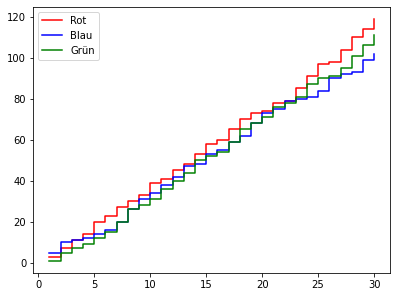

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(6)
pos = rng.integers(1, 7, size=(3, 30)).cumsum(axis=1)
runden = np.arange(1, 31)
fig, ax = plt.subplots()
for p, name, farbe in zip(pos, ['Rot', 'Blau', 'Grün'], ['red', 'blue', 'green']):
    ax.step(runden, p, where='post', color=farbe, label=name)
ax.legend()
plt.show()
```

</details>

#### Aufgabe 4.6

**Warteschlange am Kiosk:** In jeder Minute kommen 0 bis 3 Personen (`rng.integers(0, 4, size=120)`), bedient werden höchstens 2 pro Minute.
Berechne die Länge der Schlange Minute für Minute mit einer Schleife (`schlange = max(0, schlange + ankunft - 2)`) und zeichne sie über 120 Minuten. Gib die längste Schlange aus.

**Erwartete Ausgabe:**
```
4
```

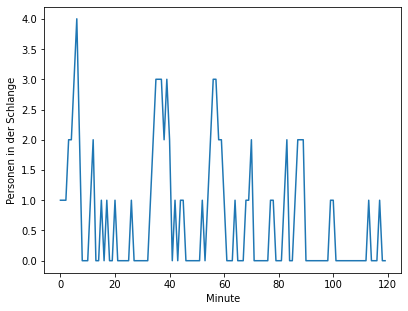

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)
ankuenfte = rng.integers(0, 4, size=120)
schlange = 0
verlauf = []
for a in ankuenfte:
    schlange = max(0, schlange + a - 2)
    verlauf.append(schlange)
fig, ax = plt.subplots()
ax.plot(verlauf)
ax.set_xlabel('Minute')
ax.set_ylabel('Personen in der Schlange')
plt.show()
print(max(verlauf))
```

</details>

## 5. Vorgänge Schritt für Schritt berechnen

#### Das Euler-Verfahren

Viele Vorgänge kennt man nur über ihre **Änderung**: Ein Tee kühlt umso schneller ab, je heißer er ist. Dann rechnet man in kleinen Zeitschritten `dt`:

```
neuer Wert = alter Wert + Änderungsrate · dt
```

Die Werte sammelt man in einer Liste und zeichnet sie am Ende. Je kleiner `dt`, desto genauer.
Mit mehreren Größen, die sich gegenseitig beeinflussen, entstehen Modelle für Epidemien, Räuber und Beute oder Würfe mit Luftwiderstand.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Abkühlung: Änderungsrate = -k · (T - Raumtemperatur)
T = 90.0
dt = 0.5
k = 0.1
zeiten = [0.0]
temperaturen = [T]
for i in range(120):
    T = T + (-k * (T - 20)) * dt
    zeiten.append(zeiten[-1] + dt)
    temperaturen.append(T)
fig, ax = plt.subplots()
ax.plot(zeiten, temperaturen, label='Euler')
t = np.linspace(0, 60, 200)
ax.plot(t, 20 + 70 * np.exp(-k * t), '--', label='exakt')
ax.legend()
plt.show()

#### Aufgabe 5.1

Berechne die Abkühlung wie im Beispiel, aber mit dem großen Zeitschritt `dt = 5` (12 Schritte), und zeichne sie mit Kreis-Markern zusammen mit der exakten Lösung (gestrichelt).
Gib die Temperatur nach 60 Minuten nach Euler und exakt aus (zwei Stellen).

**Erwartete Ausgabe:**
```
20.02 20.17
```

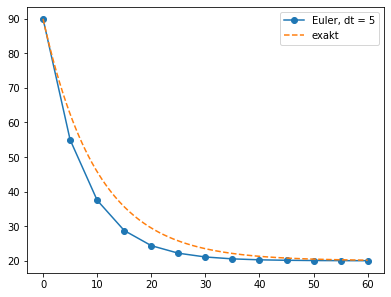

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
T = 90.0
dt = 5
werte = [T]
for i in range(12):
    T = T + (-0.1 * (T - 20)) * dt
    werte.append(T)
zeiten = np.arange(13) * dt
t = np.linspace(0, 60, 200)
fig, ax = plt.subplots()
ax.plot(zeiten, werte, 'o-', label='Euler, dt = 5')
ax.plot(t, 20 + 70 * np.exp(-0.1 * t), '--', label='exakt')
ax.legend()
plt.show()
print(np.round(werte[-1], 2), np.round(20 + 70 * np.exp(-6), 2))
```

</details>

#### Aufgabe 5.2

**SIR-Modell einer Epidemie:** Von 1000 Personen sind am Anfang 990 gesund (S), 10 infiziert (I), 0 genesen (R). Pro Tag gilt mit `b = 0.3` und `g = 0.1`:
neue Infektionen `b · S · I / 1000`, neue Genesungen `g · I`. Rechne 160 Tage in Schritten von einem Tag und zeichne S, I und R mit Legende (`gesund`, `infiziert`, `genesen`).
Gib den Tag mit den meisten Infizierten und deren Anzahl (gerundet) aus.

**Erwartete Ausgabe:**
```
28 316.0
```

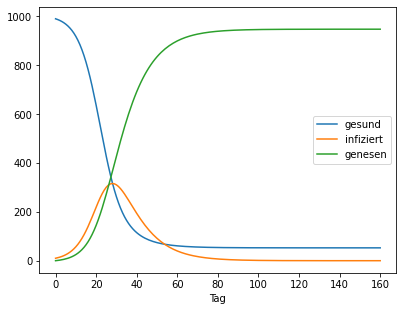

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
S, I, R = 990.0, 10.0, 0.0
verlauf = [(S, I, R)]
for tag in range(160):
    neu_inf = 0.3 * S * I / 1000
    neu_gen = 0.1 * I
    S, I, R = S - neu_inf, I + neu_inf - neu_gen, R + neu_gen
    verlauf.append((S, I, R))
v = np.array(verlauf)
fig, ax = plt.subplots()
ax.plot(v[:, 0], label='gesund')
ax.plot(v[:, 1], label='infiziert')
ax.plot(v[:, 2], label='genesen')
ax.set_xlabel('Tag')
ax.legend()
plt.show()
print(v[:, 1].argmax(), np.round(v[:, 1].max()))
```

</details>

#### Aufgabe 5.3

Vergleiche das SIR-Modell für die Ansteckungsraten `b` = 0.2, 0.3 und 0.5 (sonst wie oben): Zeichne nur die Zahl der Infizierten mit den Labels `b = 0.2` usw. und Legende.
Schreibe dazu eine Funktion `sir(b, tage)`, die das Array der Infizierten zurückgibt.

**Erwartete Ausgabe:**

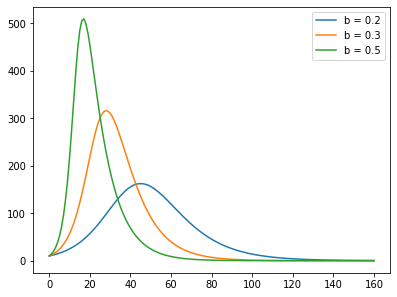

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
def sir(b, tage):
    S, I, R = 990.0, 10.0, 0.0
    infiziert = [I]
    for tag in range(tage):
        neu_inf = b * S * I / 1000
        neu_gen = 0.1 * I
        S, I, R = S - neu_inf, I + neu_inf - neu_gen, R + neu_gen
        infiziert.append(I)
    return np.array(infiziert)

fig, ax = plt.subplots()
for b in [0.2, 0.3, 0.5]:
    ax.plot(sir(b, 160), label=f'b = {b}')
ax.legend()
plt.show()
```

</details>

#### Aufgabe 5.4

**Räuber und Beute:** Hasen `H` und Füchse `F` mit `dt = 0.01`, 3000 Schritten und Start `H = 40`, `F = 9`. Änderungsraten:
Hasen `0.6·H - 0.03·H·F`, Füchse `0.01·H·F - 0.5·F`. Zeichne links (Größe 10 × 3.5) beide über der Zeit, rechts F über H (das **Phasendiagramm**).

**Erwartete Ausgabe:**

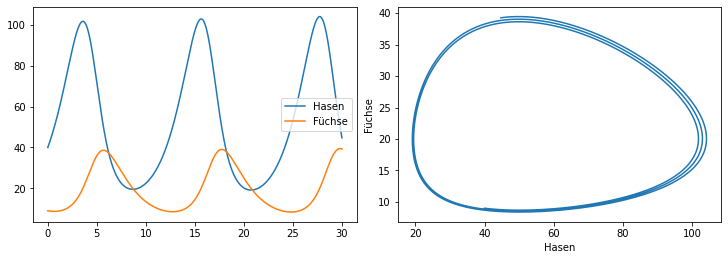

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
H, F = 40.0, 9.0
dt = 0.01
hasen = [H]
fuechse = [F]
for i in range(3000):
    H, F = H + (0.6 * H - 0.03 * H * F) * dt, F + (0.01 * H * F - 0.5 * F) * dt
    hasen.append(H)
    fuechse.append(F)
zeit = np.arange(3001) * dt
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
axs[0].plot(zeit, hasen, label='Hasen')
axs[0].plot(zeit, fuechse, label='Füchse')
axs[0].legend()
axs[1].plot(hasen, fuechse)
axs[1].set_xlabel('Hasen')
axs[1].set_ylabel('Füchse')
plt.show()
```

</details>

#### Aufgabe 5.5

**Schiefer Wurf:** Ein Ball wird mit 20 m/s unter den Winkeln 30°, 45° und 60° geworfen (ohne Luftwiderstand): `x = v·cos(α)·t`, `y = v·sin(α)·t - 4.9·t²`.
Zeichne die Flugbahnen bis zum Aufprall (für jeden Winkel 200 Zeitpunkte von 0 bis `2·v·sin(α)/9.81`) mit Labels `30°` usw., gleichen Einheiten und Legende.

**Erwartete Ausgabe:**

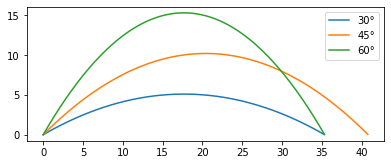

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
v = 20
fig, ax = plt.subplots()
for grad in [30, 45, 60]:
    a = np.radians(grad)
    t = np.linspace(0, 2 * v * np.sin(a) / 9.81, 200)
    ax.plot(v * np.cos(a) * t, v * np.sin(a) * t - 4.9 * t ** 2, label=f'{grad}°')
ax.set_aspect('equal')
ax.legend()
plt.show()
```

</details>

#### Aufgabe 5.6

**Wurf mit Luftwiderstand:** Berechne den 45°-Wurf mit 20 m/s mit dem Euler-Verfahren (`dt = 0.01`), einmal ohne (`k = 0`) und einmal mit Luftwiderstand (`k = 0.05`).
Beschleunigung: `ax = -k·v·vx`, `ay = -9.81 - k·v·vy` mit `v = √(vx² + vy²)`. Rechne, solange `y >= 0`. Zeichne beide Bahnen mit Legende (`ohne`, `mit Luftwiderstand`)
und gleichen Einheiten. Gib die Wurfweiten auf eine Stelle gerundet aus.

**Erwartete Ausgabe:**
```
40.7
17.3
```

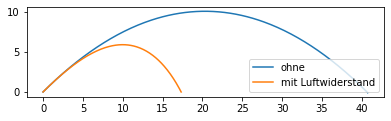

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
def wurf(k):
    x, y = 0.0, 0.0
    vx = vy = 20 * np.cos(np.radians(45))
    xs, ys = [x], [y]
    while y >= 0:
        v = np.sqrt(vx ** 2 + vy ** 2)
        vx, vy = vx - k * v * vx * 0.01, vy + (-9.81 - k * v * vy) * 0.01
        x, y = x + vx * 0.01, y + vy * 0.01
        xs.append(x)
        ys.append(y)
    return xs, ys

fig, ax = plt.subplots()
for k, name in [(0, 'ohne'), (0.05, 'mit Luftwiderstand')]:
    xs, ys = wurf(k)
    ax.plot(xs, ys, label=name)
    print(np.round(xs[-1], 1))
ax.set_aspect('equal')
ax.legend()
plt.show()
```

</details>

## 6. Geometrie mit patches

#### Kreise, Rechtecke und Vielecke

Das Modul `matplotlib.patches` enthält geometrische Figuren:

- `Circle((x, y), r)`: Kreis mit Mittelpunkt (x, y) und Radius r
- `Rectangle((x, y), breite, hoehe)`: Rechteck mit der linken unteren Ecke (x, y)
- `Polygon(punkte)`: Vieleck durch die Punkte (Liste von Paaren oder Array mit zwei Spalten)

Wichtige Parameter: `facecolor` (Füllfarbe), `edgecolor` (Randfarbe), `fill=False` (nicht gefüllt), `linewidth`, `alpha`.
Mit `ax.add_patch(figur)` kommt die Figur ins Diagramm. Weil matplotlib die Achsen dabei **nicht** automatisch anpasst,
setzt man den Bereich mit `ax.set_xlim()` und `ax.set_ylim()` und mit `ax.set_aspect('equal')` gleiche Einheiten (sonst wird ein Kreis zur Ellipse).

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon

fig, ax = plt.subplots()
ax.add_patch(Rectangle((0, 0), 4, 3, facecolor='lightblue', edgecolor='black'))
ax.add_patch(Polygon([(0, 3), (4, 3), (2, 5)], facecolor='firebrick'))
ax.add_patch(Circle((6, 4), 1, facecolor='gold'))
ax.add_patch(Circle((6, 4), 1.4, fill=False, edgecolor='orange', linewidth=3))
ax.set_xlim(-1, 8)
ax.set_ylim(-1, 6)
ax.set_aspect('equal')
plt.show()

#### Aufgabe 6.1

Zeichne die **olympischen Ringe**: fünf nicht gefüllte Kreise mit Radius 1 und Linienstärke 6 bei (0, 0) blau, (2.2, 0) schwarz, (4.4, 0) rot, (1.1, -1) gelb (`gold`), (3.3, -1) grün.
Bereich x von -1.5 bis 5.9, y von -2.5 bis 1.5, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

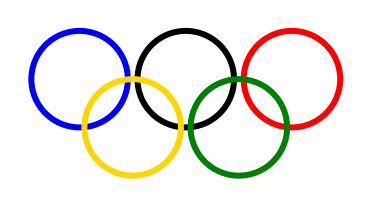

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
ringe = [((0, 0), 'blue'), ((2.2, 0), 'black'), ((4.4, 0), 'red'), ((1.1, -1), 'gold'), ((3.3, -1), 'green')]
fig, ax = plt.subplots()
for mitte, farbe in ringe:
    ax.add_patch(Circle(mitte, 1, fill=False, edgecolor=farbe, linewidth=6))
ax.set_xlim(-1.5, 5.9)
ax.set_ylim(-2.5, 1.5)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.2

Zeichne eine **Zielscheibe** aus 5 gefüllten Kreisen um (0, 0) mit den Radien 5, 4, 3, 2, 1 (in dieser Reihenfolge, damit die kleinen oben liegen), abwechselnd `'white'` und `'red'` mit schwarzem Rand.
Bereich -6 bis 6, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

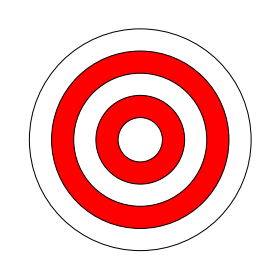

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
fig, ax = plt.subplots()
for i, r in enumerate([5, 4, 3, 2, 1]):
    farbe = 'white' if i % 2 == 0 else 'red'
    ax.add_patch(Circle((0, 0), r, facecolor=farbe, edgecolor='black'))
ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.3

Zeichne die **regelmäßigen Vielecke** mit 3 bis 8 Ecken in einem 2 × 3-Raster (Größe 9 × 6). Die Ecken liegen auf dem Einheitskreis bei den Winkeln `2π·i/n + π/2`.
Jedes Vieleck hellgrün mit dunkelgrünem Rand, Titel `n = 3` usw., Bereich -1.2 bis 1.2, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

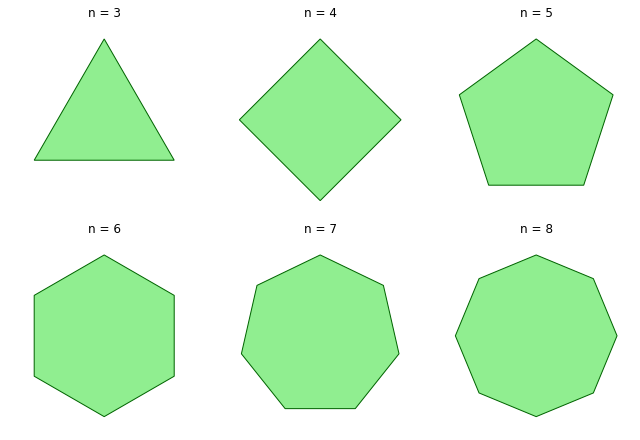

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
fig, axs = plt.subplots(2, 3, figsize=(9, 6), layout='constrained')
for ax, n in zip(axs.flat, range(3, 9)):
    w = 2 * np.pi * np.arange(n) / n + np.pi / 2
    ax.add_patch(Polygon(np.column_stack([np.cos(w), np.sin(w)]), facecolor='lightgreen', edgecolor='darkgreen'))
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_title(f'n = {n}')
    ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.4

**π mit Vielecken (Archimedes):** Der halbe Umfang eines regelmäßigen n-Ecks im Einheitskreis ist `n·sin(π/n)`. Zeichne den Einheitskreis (nicht gefüllt) und das
eingeschriebene 6-Eck, 12-Eck und 24-Eck in drei Diagrammen nebeneinander (Größe 9 × 3, Titel `n = 6` usw.). Gib danach für jedes n die Näherung für π aus (6 Stellen).

**Erwartete Ausgabe:**
```
6 3.0
12 3.105829
24 3.132629
96 3.141032
1000 3.141587
```

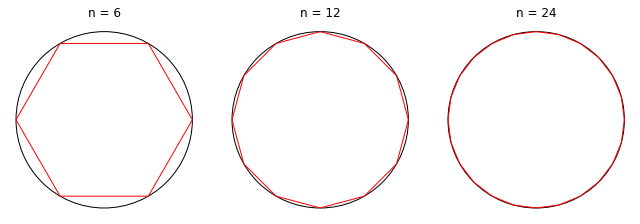

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
fig, axs = plt.subplots(1, 3, figsize=(9, 3), layout='constrained')
for ax, n in zip(axs, [6, 12, 24]):
    w = 2 * np.pi * np.arange(n) / n
    ax.add_patch(Circle((0, 0), 1, fill=False, edgecolor='black'))
    ax.add_patch(Polygon(np.column_stack([np.cos(w), np.sin(w)]), fill=False, edgecolor='red'))
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_aspect('equal')
    ax.set_title(f'n = {n}')
    ax.axis('off')
plt.show()
for n in [6, 12, 24, 96, 1000]:
    print(n, np.round(n * np.sin(np.pi / n), 6))
```

</details>

#### Aufgabe 6.5

Zeichne den **Satz des Pythagoras**: das rechtwinklige Dreieck mit den Ecken (0, 0), (4, 0), (0, 3) (grau) und die Quadrate über den drei Seiten
(über a: (0, 0), (4, 0), (4, -4), (0, -4) in Rot; über b: (0, 0), (0, 3), (-3, 3), (-3, 0) in Blau; über c: (4, 0), (0, 3), (3, 7), (7, 4) in Grün), alle mit Deckkraft 0.5.
Schreibe die Flächen `16`, `9` und `25` in die Mitte der Quadrate (Schriftgröße 16). Bereich x von -4 bis 8, y von -5 bis 8, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

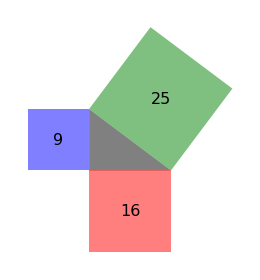

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
fig, ax = plt.subplots()
ax.add_patch(Polygon([(0, 0), (4, 0), (0, 3)], facecolor='gray'))
ax.add_patch(Polygon([(0, 0), (4, 0), (4, -4), (0, -4)], facecolor='red', alpha=0.5))
ax.add_patch(Polygon([(0, 0), (0, 3), (-3, 3), (-3, 0)], facecolor='blue', alpha=0.5))
ax.add_patch(Polygon([(4, 0), (0, 3), (3, 7), (7, 4)], facecolor='green', alpha=0.5))
ax.text(2, -2, '16', fontsize=16, ha='center', va='center')
ax.text(-1.5, 1.5, '9', fontsize=16, ha='center', va='center')
ax.text(3.5, 3.5, '25', fontsize=16, ha='center', va='center')
ax.set_xlim(-4, 8)
ax.set_ylim(-5, 8)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.6

Zeichne ein **zufälliges Kunstwerk**: 40 Kreise mit Mittelpunkten `rng.random((40, 2)) * 10`, danach Radien `rng.uniform(0.2, 1.5, size=40)` und danach Farbwerte `rng.random(40)`.
Die Farbe von Kreis `i` ist `plt.colormaps['viridis'](farbwert[i])`, Deckkraft 0.6. Bereich 0 bis 10, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

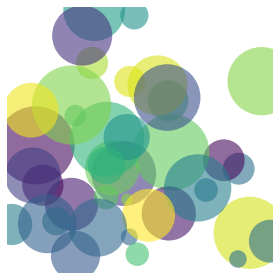

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
rng = np.random.default_rng(8)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
rng = np.random.default_rng(8)
mitten = rng.random((40, 2)) * 10
radien = rng.uniform(0.2, 1.5, size=40)
farbwerte = rng.random(40)
skala = plt.colormaps['viridis']
fig, ax = plt.subplots()
for i in range(40):
    ax.add_patch(Circle(mitten[i], radien[i], facecolor=skala(farbwerte[i]), alpha=0.6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.7

Zeichne ein **Schachbrett** aus 64 Quadraten mit `Rectangle` (Seitenlänge 1, abwechselnd `'saddlebrown'` und `'wheat'`, unten links dunkel) und einen roten Kreis (Radius 0.35) als Spielfigur
auf dem Feld in Spalte 4, Zeile 6 (Mittelpunkt bei (4.5, 6.5)). Bereich 0 bis 8, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

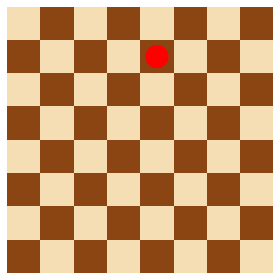

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon
fig, ax = plt.subplots()
for zeile in range(8):
    for spalte in range(8):
        farbe = 'saddlebrown' if (zeile + spalte) % 2 == 0 else 'wheat'
        ax.add_patch(Rectangle((spalte, zeile), 1, 1, facecolor=farbe))
ax.add_patch(Circle((4.5, 6.5), 0.35, facecolor='red'))
ax.set_xlim(0, 8)
ax.set_ylim(0, 8)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

## 7. Fraktale

#### Rekursive Figuren

Ein **Fraktal** ist eine Figur, die in sich selbst verkleinerte Kopien von sich enthält. Man erzeugt sie mit **Rekursion**:
Eine Funktion zeichnet ein Stück und ruft sich für die kleineren Teile selbst auf, bis eine Tiefe von 0 erreicht ist.

Beim **Fraktal-Baum** zeichnet die Funktion einen Ast und ruft sich für zwei kürzere, gedrehte Äste an dessen Ende auf.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def ast(ax, x, y, winkel, laenge, tiefe):
    if tiefe == 0:
        return
    x2 = x + laenge * np.cos(winkel)
    y2 = y + laenge * np.sin(winkel)
    ax.plot([x, x2], [y, y2], color='saddlebrown', linewidth=tiefe)
    ast(ax, x2, y2, winkel + 0.4, laenge * 0.7, tiefe - 1)
    ast(ax, x2, y2, winkel - 0.4, laenge * 0.7, tiefe - 1)

fig, ax = plt.subplots()
ast(ax, 0, 0, np.pi / 2, 1, 8)
ax.set_aspect('equal')
ax.axis('off')
plt.show()

#### Komplexe Zahlen und die Mandelbrot-Menge

Python kann mit **komplexen Zahlen** rechnen: `3 + 2j` ist die Zahl mit Realteil 3 und Imaginärteil 2, wobei `j * j == -1`.
`abs(z)` ist der Abstand vom Nullpunkt. Mit numpy kann man ein ganzes Raster komplexer Zahlen erzeugen: `C = X + 1j * Y`.

Für die **Mandelbrot-Menge** rechnet man für jede Zahl `c` immer wieder `z = z² + c`, beginnend bei `z = 0`.
Wird `|z|` irgendwann größer als 2, flieht die Folge ins Unendliche. Die Farbe zeigt, nach wie vielen Schritten das passiert.
Punkte, die nie fliehen, gehören zur Menge. Damit die Zahlen nicht riesig werden, rechnet man nur mit den Punkten weiter, die noch nicht geflohen sind (Maske).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

z = 3 + 2j
print(z * z, abs(3 + 4j), (1j) ** 2)

x = np.linspace(-2, 0.6, 300)
y = np.linspace(-1.2, 1.2, 250)
X, Y = np.meshgrid(x, y)
C = X + 1j * Y
Z = np.zeros_like(C)
schritte = np.zeros(C.shape, dtype=int)
for i in range(40):
    drin = np.abs(Z) <= 2
    Z[drin] = Z[drin] ** 2 + C[drin]
    schritte[drin] += 1
fig, ax = plt.subplots()
ax.imshow(schritte, cmap='magma', origin='lower', extent=(-2, 0.6, -1.2, 1.2))
plt.show()

#### Aufgabe 7.1

Zeichne den Fraktal-Baum aus dem Beispiel mit Tiefe 10, dem Drehwinkel 0.5 und dem Verkürzungsfaktor 0.72 in Grün (`'forestgreen'`). Gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

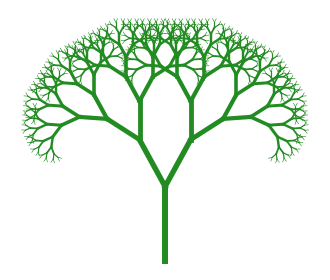

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
def ast(ax, x, y, winkel, laenge, tiefe):
    if tiefe == 0:
        return
    x2 = x + laenge * np.cos(winkel)
    y2 = y + laenge * np.sin(winkel)
    ax.plot([x, x2], [y, y2], color='forestgreen', linewidth=tiefe * 0.6)
    ast(ax, x2, y2, winkel + 0.5, laenge * 0.72, tiefe - 1)
    ast(ax, x2, y2, winkel - 0.5, laenge * 0.72, tiefe - 1)

fig, ax = plt.subplots()
ast(ax, 0, 0, np.pi / 2, 1, 10)
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.2

**Koch-Kurve:** Eine Strecke von `a` nach `b` wird gedrittelt, über dem mittleren Drittel entsteht eine Spitze (das Drittel um 60° gedreht). Die Funktion `koch(a, b, tiefe)` ist vorgegeben
und liefert die Liste der Punkte. Zeichne die Kurven der Tiefe 0 bis 3 untereinander (Größe 6 × 6, gemeinsame Achsen, Titel `Tiefe 0` usw., gleiche Einheiten, ohne Achsen).

**Erwartete Ausgabe:**

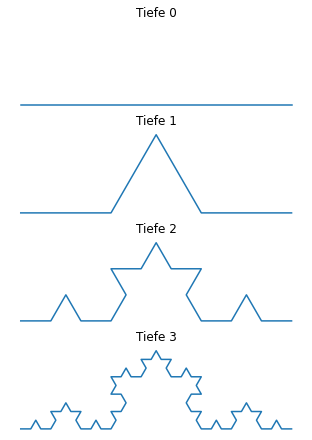

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def koch(a, b, tiefe):
    if tiefe == 0:
        return [a, b]
    d = (b - a) / 3
    p1 = a + d
    p3 = a + 2 * d
    c, s = np.cos(np.pi / 3), np.sin(np.pi / 3)
    spitze = p1 + np.array([c * d[0] - s * d[1], s * d[0] + c * d[1]])
    punkte = []
    for von, bis in [(a, p1), (p1, spitze), (spitze, p3), (p3, b)]:
        punkte += koch(von, bis, tiefe - 1)[:-1]
    return punkte + [b]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt

def koch(a, b, tiefe):
    if tiefe == 0:
        return [a, b]
    d = (b - a) / 3
    p1 = a + d
    p3 = a + 2 * d
    c, s = np.cos(np.pi / 3), np.sin(np.pi / 3)
    spitze = p1 + np.array([c * d[0] - s * d[1], s * d[0] + c * d[1]])
    punkte = []
    for von, bis in [(a, p1), (p1, spitze), (spitze, p3), (p3, b)]:
        punkte += koch(von, bis, tiefe - 1)[:-1]
    return punkte + [b]
fig, axs = plt.subplots(4, 1, figsize=(6, 6), sharex=True, sharey=True, layout='constrained')
for tiefe, ax in enumerate(axs):
    p = np.array(koch(np.array([0.0, 0.0]), np.array([1.0, 0.0]), tiefe))
    ax.plot(p[:, 0], p[:, 1])
    ax.set_title(f'Tiefe {tiefe}')
    ax.set_aspect('equal')
    ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.3

**Koch-Schneeflocke:** Verwende die Funktion `koch()` für die drei Seiten des gleichseitigen Dreiecks mit den Ecken A = (0, 0), B = (0.5, √3/2) und C = (1, 0),
in der Reihenfolge A→B, B→C, C→A (Tiefe 4). Fülle die Schneeflocke hellblau (`ax.fill(x, y, ...)`) mit blauem Rand. Gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

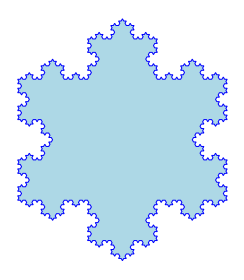

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def koch(a, b, tiefe):
    if tiefe == 0:
        return [a, b]
    d = (b - a) / 3
    p1 = a + d
    p3 = a + 2 * d
    c, s = np.cos(np.pi / 3), np.sin(np.pi / 3)
    spitze = p1 + np.array([c * d[0] - s * d[1], s * d[0] + c * d[1]])
    punkte = []
    for von, bis in [(a, p1), (p1, spitze), (spitze, p3), (p3, b)]:
        punkte += koch(von, bis, tiefe - 1)[:-1]
    return punkte + [b]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt

def koch(a, b, tiefe):
    if tiefe == 0:
        return [a, b]
    d = (b - a) / 3
    p1 = a + d
    p3 = a + 2 * d
    c, s = np.cos(np.pi / 3), np.sin(np.pi / 3)
    spitze = p1 + np.array([c * d[0] - s * d[1], s * d[0] + c * d[1]])
    punkte = []
    for von, bis in [(a, p1), (p1, spitze), (spitze, p3), (p3, b)]:
        punkte += koch(von, bis, tiefe - 1)[:-1]
    return punkte + [b]
A = np.array([0.0, 0.0])
B = np.array([0.5, np.sqrt(3) / 2])
C = np.array([1.0, 0.0])
punkte = koch(A, B, 4)[:-1] + koch(B, C, 4)[:-1] + koch(C, A, 4)
p = np.array(punkte)
fig, ax = plt.subplots()
ax.fill(p[:, 0], p[:, 1], facecolor='lightblue', edgecolor='blue')
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.4

**Chaos-Spiel (Sierpinski-Dreieck):** Starte bei (0.5, 0.3). Wiederhole 5000-mal: Wähle eine der drei Ecken (0, 0), (1, 0), (0.5, 0.87) zufällig
(die Indizes vorher mit `rng.integers(0, 3, size=5000)` erzeugen) und springe auf die Mitte zwischen aktuellem Punkt und Ecke. Zeichne alle Punkte (Größe 0.5, schwarz), gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

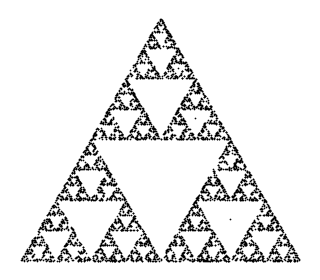

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(9)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(9)
ecken = np.array([[0, 0], [1, 0], [0.5, 0.87]])
wahl = rng.integers(0, 3, size=5000)
p = np.array([0.5, 0.3])
punkte = []
for i in wahl:
    p = (p + ecken[i]) / 2
    punkte.append(p)
punkte = np.array(punkte)
fig, ax = plt.subplots()
ax.scatter(punkte[:, 0], punkte[:, 1], s=0.5, color='black')
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.5

Berechne die Mandelbrot-Menge wie im Beispiel, aber mit 60 Schritten, der Farbskala `'twilight_shifted'` und einer feineren Auflösung (x: 400 Punkte, y: 330 Punkte). Ohne Achsen.

**Erwartete Ausgabe:**

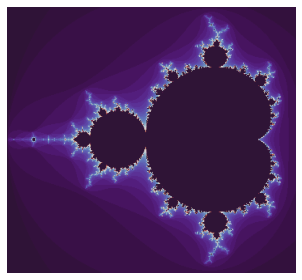

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-2, 0.6, 400)
y = np.linspace(-1.2, 1.2, 330)
X, Y = np.meshgrid(x, y)
C = X + 1j * Y
Z = np.zeros_like(C)
schritte = np.zeros(C.shape, dtype=int)
for i in range(60):
    drin = np.abs(Z) <= 2
    Z[drin] = Z[drin] ** 2 + C[drin]
    schritte[drin] += 1
fig, ax = plt.subplots()
ax.imshow(schritte, cmap='twilight_shifted', origin='lower', extent=(-2, 0.6, -1.2, 1.2))
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.6

Schreibe eine Funktion `mandelbrot(xmin, xmax, ymin, ymax, n, schritte)`, die das Array der Schrittzahlen für ein `n × n`-Raster zurückgibt.
Zeige damit einen vergrößerten Ausschnitt: x von -0.75 bis -0.73, y von 0.10 bis 0.12, 300 × 300 Punkte, 150 Schritte, `cmap='inferno'`, ohne Achsen.

**Erwartete Ausgabe:**

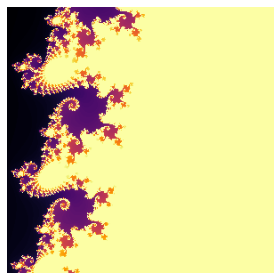

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
def mandelbrot(xmin, xmax, ymin, ymax, n, schritte):
    X, Y = np.meshgrid(np.linspace(xmin, xmax, n), np.linspace(ymin, ymax, n))
    C = X + 1j * Y
    Z = np.zeros_like(C)
    anzahl = np.zeros(C.shape, dtype=int)
    for i in range(schritte):
        drin = np.abs(Z) <= 2
        Z[drin] = Z[drin] ** 2 + C[drin]
        anzahl[drin] += 1
    return anzahl

fig, ax = plt.subplots()
ax.imshow(mandelbrot(-0.75, -0.73, 0.10, 0.12, 300, 150), cmap='inferno', origin='lower')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.7

**Julia-Menge:** Wie bei Mandelbrot, aber `c = -0.8 + 0.156j` ist für alle Punkte gleich, und der **Startwert** `z` ist die jeweilige Zahl des Rasters
(x von -1.6 bis 1.6 mit 400 Punkten, y von -1 bis 1 mit 250 Punkten, 80 Schritte). Zeige das Ergebnis mit `cmap='plasma'` ohne Achsen.

**Erwartete Ausgabe:**

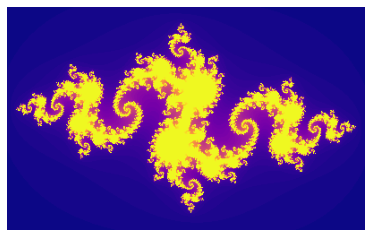

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
X, Y = np.meshgrid(np.linspace(-1.6, 1.6, 400), np.linspace(-1, 1, 250))
Z = X + 1j * Y
c = -0.8 + 0.156j
anzahl = np.zeros(Z.shape, dtype=int)
for i in range(80):
    drin = np.abs(Z) <= 2
    Z[drin] = Z[drin] ** 2 + c
    anzahl[drin] += 1
fig, ax = plt.subplots()
ax.imshow(anzahl, cmap='plasma', origin='lower')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 7.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
z = 1 + 1j
print(z * z)
print(abs(z) ** 2)
c = 0
for i in range(4):
    c = c * c + 1j
    print(c)

## 8. Gemischte Übungen

#### Aufgabe 8.1

Erstelle einen **Steckbrief** einer Funktion in einem 2 × 2-Raster (Größe 9 × 7, Überschrift `f(x) = x⁴ - 4x²`): oben links den Graphen mit Nullstellen (rot) und Extrempunkten (grün),
oben rechts die Ableitung, unten links die Fläche zwischen den äußeren Nullstellen (Deckkraft 0.3), unten rechts eine Wertetabelle als Heatmap der Funktionswerte für x = -2, -1.5, ..., 2
(eine Zeile, `cmap='coolwarm'`, Werte mit einer Nachkommastelle in den Feldern). Titel: `Graph`, `Ableitung`, `Fläche`, `Werte`.

**Erwartete Ausgabe:**

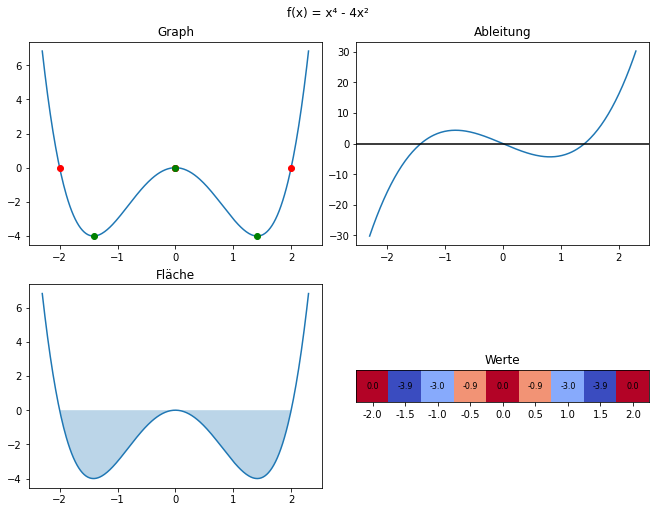

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, 0, -4, 0, 0])
x = np.linspace(-2.3, 2.3, 300)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
f = np.array([1, 0, -4, 0, 0])
x = np.linspace(-2.3, 2.3, 300)
null = np.sort(np.roots(f).real)
extrem = np.sort(np.roots(np.polyder(f)).real)
fig, axs = plt.subplots(2, 2, figsize=(9, 7), layout='constrained')
axs[0, 0].plot(x, np.polyval(f, x))
axs[0, 0].plot(null, np.zeros(len(null)), 'ro')
axs[0, 0].plot(extrem, np.polyval(f, extrem), 'go')
axs[0, 0].set_title('Graph')
axs[0, 1].plot(x, np.polyval(np.polyder(f), x))
axs[0, 1].axhline(0, color='black')
axs[0, 1].set_title('Ableitung')
xf = np.linspace(null[0], null[-1], 300)
axs[1, 0].plot(x, np.polyval(f, x))
axs[1, 0].fill_between(xf, np.polyval(f, xf), alpha=0.3)
axs[1, 0].set_title('Fläche')
xw = np.arange(-2, 2.1, 0.5)
yw = np.polyval(f, xw)
axs[1, 1].imshow(yw.reshape(1, -1), cmap='coolwarm')
for i in range(len(xw)):
    axs[1, 1].text(i, 0, f'{yw[i]:.1f}', ha='center', va='center', fontsize=8)
axs[1, 1].set_xticks(range(len(xw)), xw)
axs[1, 1].set_yticks([])
axs[1, 1].set_title('Werte')
fig.suptitle('f(x) = x⁴ - 4x²')
plt.show()
```

</details>

#### Aufgabe 8.2

**Lissajous-Figuren:** Zeichne `x = sin(a·t)`, `y = sin(b·t)` für `t` von 0 bis 2π (1000 Punkte) in einem 3 × 3-Raster (Größe 7 × 7) für `a` = 1, 2, 3 (Zeilen) und `b` = 1, 2, 3 (Spalten),
mit dem Titel `a:b` (z. B. `1:2`), gleichen Einheiten und ohne Achsen.

**Erwartete Ausgabe:**

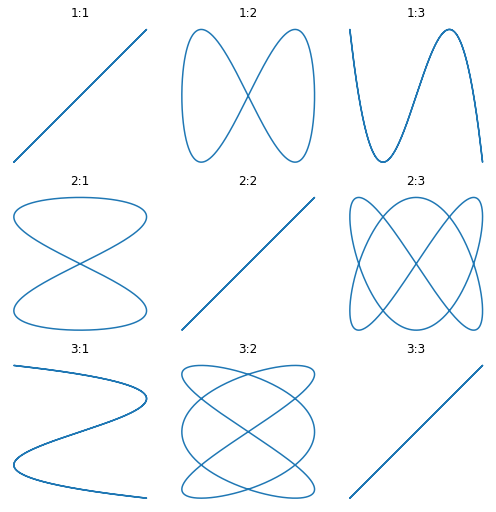

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
t = np.linspace(0, 2 * np.pi, 1000)
fig, axs = plt.subplots(3, 3, figsize=(7, 7), layout='constrained')
for a in range(1, 4):
    for b in range(1, 4):
        ax = axs[a - 1, b - 1]
        ax.plot(np.sin(a * t), np.sin(b * t))
        ax.set_title(f'{a}:{b}')
        ax.set_aspect('equal')
        ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 8.3

**Sonnenblume:** Zeichne 500 Kerne als Punkte. Kern `k` (von 1 bis 500) liegt beim Winkel `k · 137.5°` (in Bogenmaß umrechnen) und im Abstand `√k` vom Mittelpunkt.
Größe 20, Farbe nach `k` mit `cmap='YlOrBr'`, gleiche Einheiten, ohne Achsen.

**Erwartete Ausgabe:**

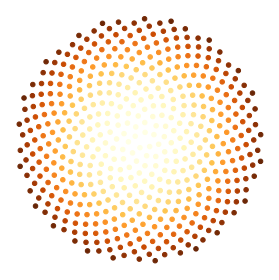

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
k = np.arange(1, 501)
w = np.radians(k * 137.5)
r = np.sqrt(k)
fig, ax = plt.subplots()
ax.scatter(r * np.cos(w), r * np.sin(w), s=20, c=k, cmap='YlOrBr')
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>

#### Aufgabe 8.4

**Waldbrand-Modell:** Ein 40 × 40-Wald (`rng.random((40, 40)) < 0.65` sind Bäume = 1) brennt von der linken Spalte aus (dort werden Bäume zu 2 = Feuer).
In jedem Schritt fängt jeder Baum Feuer, der oben, unten, links oder rechts an ein Feuer grenzt, und Feuer wird zu Asche (3). Rechne 15 Schritte und zeige den Zustand nach 0, 5, 10 und 15 Schritten
nebeneinander (Größe 10 × 3, Farben `'white'`, `'forestgreen'`, `'orangered'`, `'dimgray'` für 0 bis 3, `vmin=0`, `vmax=3`, Titel `Schritt 0` usw., ohne Achsen).

**Erwartete Ausgabe:**

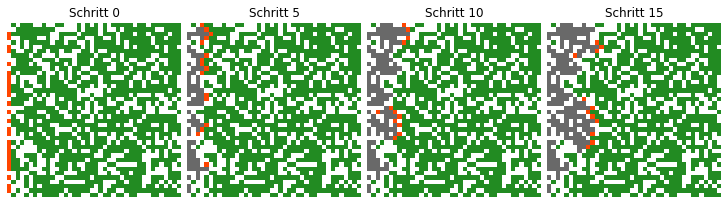

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
rng = np.random.default_rng(10)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
rng = np.random.default_rng(10)
wald = (rng.random((40, 40)) < 0.65).astype(int)
wald[:, 0][wald[:, 0] == 1] = 2
farben = ListedColormap(['white', 'forestgreen', 'orangered', 'dimgray'])
fig, axs = plt.subplots(1, 4, figsize=(10, 3), layout='constrained')
nr = 0
for schritt in range(16):
    if schritt % 5 == 0:
        axs[nr].imshow(wald, cmap=farben, vmin=0, vmax=3)
        axs[nr].set_title(f'Schritt {schritt}')
        axs[nr].axis('off')
        nr += 1
    feuer = np.pad(wald == 2, 1)
    nachbar = feuer[:-2, 1:-1] | feuer[2:, 1:-1] | feuer[1:-1, :-2] | feuer[1:-1, 2:]
    neu = wald.copy()
    neu[(wald == 1) & nachbar] = 2
    neu[wald == 2] = 3
    wald = neu
plt.show()
```

</details>

#### Aufgabe 8.5

Zeichne mit numpy und matplotlib ein eigenes Bild: eine Landschaft, ein Muster, ein Fraktal mit anderen Parametern oder eine Simulation deiner Wahl.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 10, 300)
fig, ax = plt.subplots()
ax.fill_between(x, 0, 2 + np.sin(x) + 0.3 * np.sin(5 * x), color='forestgreen')
ax.fill_between(x, 2 + np.sin(x) + 0.3 * np.sin(5 * x), 6, color='skyblue')
ax.add_patch(plt.Circle((8, 5), 0.5, color='gold'))
ax.set_aspect('equal')
ax.axis('off')
plt.show()
```

</details>